[![../img/pythonista.png](../img/pythonista.png)](https://www.pythonista.io)

# Calidad de datos y valores faltantes.

**py401 · EDA Práctico** · Pythonista® · Instructor: José Luis Chiquete
**Martes 20 de octubre de 2026 · 6:30 a 8:30 pm (CDMX)** · Módulo I: *Datos y su calidad*

> 🔑 **Versión con soluciones.** Solo para el instructor o para revisión posterior.

En esta sesión se auditará la calidad de un *dataset* (duplicados, inconsistencias de texto, rangos imposibles y unidades), se perfilarán los mecanismos de faltantes (MCAR, MAR, MNAR) y se compararán estrategias de tratamiento y su efecto en las distribuciones, usando `titanic` y `penguins`. Al final se genera `data/penguins_limpio.csv`.

## 🎯 Objetivo de la sesión.

**Auditar la calidad de un *dataset* y elegir de forma justificada cómo tratar los faltantes.**

Al terminar podrás:
1. Aplicar una lista de verificación de calidad a cualquier *dataset*.
2. Detectar y resolver duplicados exactos y por llave.
3. Corregir inconsistencias de texto, categorías mal escritas, rangos imposibles y unidades.
4. Distinguir los mecanismos de faltantes (MCAR, MAR, MNAR) y perfilarlos.
5. Comparar eliminación, imputación simple, imputación por grupo e indicador de faltante, y medir su efecto en las distribuciones.

## 🗺️ Agenda (120 min).

| Min | Bloque |
|---|---|
| 10 | Repaso y lista de verificación de calidad |
| 20 | 1. Duplicados: exactos y por llave |
| 25 | 2. Inconsistencias: texto, categorías, rangos imposibles, unidades |
| 15 | 3. Mecanismos de faltantes y cómo perfilarlos |
| 30 | 4. Tratamiento de faltantes y su efecto en las distribuciones |
| 20 | 5. Ejercicio (`titanic` + `penguins`) y cierre |

🟢 = ejercicio básico · 🔴 = reto opcional

## 📚 Referencia de la API: curso py311.

Los métodos de limpieza (`isna`, `notna`, `fillna`, `interpolate`, `dropna`, `duplicated`, `drop_duplicates`, …) se explican uno por uno en [py311 · 20 Limpieza y datos faltantes](https://github.com/PythonistaMX/py311/blob/main/20_limpieza_y_datos_faltantes.ipynb), y el accesor `.str` en [py311 · 23 El accesor `str` de *pandas*](https://github.com/PythonistaMX/py311/blob/main/23_el_accesor_str_de_pandas.ipynb). Aquí se usan sin repasarlos a detalle: la sesión se dedica a **decidir** qué hacer con cada problema de calidad y a medir las consecuencias.

> ⚠️ **Nota:** py311 se escribió para *pandas* 2 y este curso usa *pandas* 3. Allá las columnas de texto aparecen como `object` y se usa `inplace=True`; aquí el texto es `str` y se **reasigna** (`df["col"] = df["col"].fillna(...)`) o se usa `df.loc[...] = ...`, como se explicó en la sección 2.1 del *notebook* 01.

### Preparación del entorno.

* La siguiente celda importará las bibliotecas y definirá `DATA` y la semilla `rng`.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA = next(os.path.join(p, "data") for p in (os.curdir, os.pardir)
            if os.path.isfile(os.path.join(p, "data", "penguins.csv")))
pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")
rng = np.random.default_rng(401)

* La siguiente celda leerá `penguins` y `titanic` y mostrará su forma.

In [2]:
pinguinos = pd.read_csv(os.path.join(DATA, "penguins.csv"))
titanic = pd.read_csv(os.path.join(DATA, "titanic.csv"))
pinguinos.shape, titanic.shape

((344, 7), (891, 15))

---
## 0. Repaso y lista de verificación de calidad (10 min).

En la sesión 1 se construyó el diccionario de datos y se vio que `penguins` tiene faltantes. Hoy se auditarán con orden. Esta es la **lista de verificación** que se usará en todo el curso y en el proyecto:

| # | Pregunta | Herramientas |
|---|---|---|
| 1 | ¿Forma y tipos correctos? | `shape`, `info`, `dtypes` |
| 2 | ¿Hay una llave? ¿Es única? | `duplicated(subset=...)`, `nunique` |
| 3 | ¿Filas duplicadas exactas? | `duplicated()`, `drop_duplicates()` |
| 4 | ¿Categorías consistentes? | `value_counts(dropna=False)`, `str.strip`, `str.lower` |
| 5 | ¿Valores en rangos posibles? ¿Unidades homogéneas? | `describe`, `between`, reglas de dominio |
| 6 | ¿Cuántos faltantes, dónde y por qué? | `isna().sum()`, patrones por grupo |
| 7 | ¿Qué decisión se toma y cómo afecta? | comparar antes y después |

**Nota:** nunca se limpia "en silencio". Cada decisión se **documenta** y se **cuantifica**: cuántas filas afecta y cómo cambia el resultado.

### 🟢 Ejercicio 1 · Perfil rápido reutilizable.

Escribe una función `perfil_rapido(df)` que devuelva un *dataframe* con una fila por columna y las columnas `dtype`, `n_faltantes`, `pct_faltantes` (0 a 100, con 1 decimal), `n_unicos` y `ejemplo` (el primer valor no nulo). Pruébala con `pinguinos` y con `titanic`. Te servirá en el resto del curso.

* La siguiente celda muestra una solución posible.

In [3]:
def perfil_rapido(df):
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_faltantes": df.isna().sum(),
        "pct_faltantes": (df.isna().mean() * 100).round(1),
        "n_unicos": df.nunique(dropna=True),
        "ejemplo": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df.columns],
    })

perfil_rapido(pinguinos)

,dtype,n_faltantes,pct_faltantes,n_unicos,ejemplo
species,str,0,0.0,3,Adelie
island,str,0,0.0,3,Torgersen
bill_length_mm,float64,2,0.6,164,39.1
bill_depth_mm,float64,2,0.6,80,18.7
flipper_length_mm,float64,2,0.6,55,181.0
body_mass_g,float64,2,0.6,94,3750.0
sex,str,11,3.2,2,MALE


* La siguiente celda aplicará `perfil_rapido` a `titanic`, ordenado por porcentaje de faltantes.

In [4]:
perfil_rapido(titanic).sort_values("pct_faltantes", ascending=False) if perfil_rapido(titanic) is not None else None

,dtype,n_faltantes,pct_faltantes,n_unicos,ejemplo
deck,str,688,77.2,7,C
age,float64,177,19.9,88,22.0
embarked,str,2,0.2,3,S
embark_town,str,2,0.2,3,Southampton
sex,str,0,0.0,2,male
pclass,int64,0,0.0,3,3
survived,int64,0,0.0,2,0
fare,float64,0,0.0,248,7.25
parch,int64,0,0.0,7,0
sibsp,int64,0,0.0,7,1


---
## 1. Duplicados: exactos y por llave (20 min).

* **Duplicado exacto:** toda la fila se repite. Suele deberse a cargas repetidas o *joins* mal hechos.
* **Duplicado por llave:** la llave (por ejemplo, `id`) se repite aunque otras columnas difieran. Es más delicado: hay que **decidir qué registro es el bueno**.

Repaso: `df.duplicated()` marca cada fila que **ya apareció antes** (`keep=False` marca todas las copias) y `drop_duplicates` las elimina; el detalle está en [py311 · 20](https://github.com/PythonistaMX/py311/blob/main/20_limpieza_y_datos_faltantes.ipynb). La parte difícil no es el método sino la **política**: qué registro se conserva y por qué.

* La siguiente celda creará un pequeño registro de inscripciones al curso.

In [5]:
inscripciones = pd.DataFrame({
    "id_alumno": [101, 102, 103, 102, 104, 105, 105],
    "nombre": ["Ana", "Luis", "Marta", "Luis", "Iván", "Sofía", "Sofía"],
    "correo": ["ana@x.mx", "luis@x.mx", "marta@x.mx", "luis@x.mx", "ivan@x.mx", "sofia@x.mx", "sofia.r@x.mx"],
    "fecha": ["2026-10-01", "2026-10-02", "2026-10-02", "2026-10-02", "2026-10-05", "2026-10-06", "2026-10-09"],
})
inscripciones.duplicated().sum(), inscripciones.duplicated(subset=["id_alumno"]).sum()

(np.int64(1), np.int64(2))

* La siguiente celda mostrará todas las filas cuyo `id_alumno` está repetido.

In [6]:
inscripciones[inscripciones.duplicated(subset=["id_alumno"], keep=False)]

,id_alumno,nombre,correo,fecha
1,102,Luis,luis@x.mx,2026-10-02
3,102,Luis,luis@x.mx,2026-10-02
5,105,Sofía,sofia@x.mx,2026-10-06
6,105,Sofía,sofia.r@x.mx,2026-10-09


* La siguiente celda aplicará una política explícita: conservar el registro **más reciente** de cada alumno.

In [7]:
(
    inscripciones
    .sort_values("fecha")
    .drop_duplicates(subset=["id_alumno"], keep="last")
    .sort_values("id_alumno")
)

,id_alumno,nombre,correo,fecha
0,101,Ana,ana@x.mx,2026-10-01
3,102,Luis,luis@x.mx,2026-10-02
2,103,Marta,marta@x.mx,2026-10-02
4,104,Iván,ivan@x.mx,2026-10-05
6,105,Sofía,sofia.r@x.mx,2026-10-09


### ¿Todo duplicado exacto es un error? El caso `titanic`.

* La siguiente celda contará las filas de `titanic` idénticas a otra anterior y su proporción.

In [8]:
n_duplicados = titanic.duplicated().sum()
n_duplicados, round(n_duplicados / len(titanic), 3)

(np.int64(107), np.float64(0.12))

* La siguiente celda mostrará algunos de esos duplicados.

In [9]:
titanic[titanic.duplicated(keep=False)].sort_values(["class", "sex", "age"]).head(6)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
369,1,1,female,24.0,0,0,69.3000,C,First,woman,False,B,Cherbourg,yes,True
641,1,1,female,24.0,0,0,69.3000,C,First,woman,False,B,Cherbourg,yes,True
64,0,1,male,NaN,0,0,27.7208,C,First,man,True,NaN,Cherbourg,no,True
295,0,1,male,NaN,0,0,27.7208,C,First,man,True,NaN,Cherbourg,no,True
443,1,2,female,28.0,0,0,13.0000,S,Second,woman,False,NaN,Southampton,yes,True
635,1,2,female,28.0,0,0,13.0000,S,Second,woman,False,NaN,Southampton,yes,True


`titanic` **no tiene llave** (no hay nombre ni número de boleto). Dos hombres de tercera clase, sin edad registrada, que embarcaron en Southampton y pagaron la misma tarifa son **personas distintas** con los mismos atributos. Borrar esas filas eliminaría pasajeros reales y sesgaría el análisis.

**Nota:** sin una llave, un duplicado exacto es solo **sospechoso**, no necesariamente un error. Se decide con conocimiento del origen de los datos.

### Un *dataset* "sucio" para practicar.

La función `ensuciar_pinguinos` toma `penguins` y le introduce, con semilla fija, problemas típicos del mundo real: una llave `id_muestra`, duplicados, texto inconsistente, unidades mezcladas y códigos imposibles. **No es necesario estudiarla**: el trabajo consiste en *descubrir* los problemas como si no se supiera qué tiene.

* La siguiente celda definirá `ensuciar_pinguinos`.

In [10]:
def ensuciar_pinguinos(df, semilla=401):
    r = np.random.default_rng(semilla)
    d = df.copy().reset_index(drop=True)
    d.insert(0, "id_muestra", [f"P{i:04d}" for i in range(1, len(d) + 1)])
    con_medidas = d.index[d["body_mass_g"].notna()]

    variantes = {"Adelie": ["adelie", " Adelie", "ADELIE", "Adelie "],
                 "Gentoo": ["gentoo", "Gentoo ", "Gentoo penguin"],
                 "Chinstrap": ["chinstrap", "Chinstrap ", "Chinstarp"]}
    for i in r.choice(len(d), 30, replace=False):
        d.loc[i, "species"] = str(r.choice(variantes[d.loc[i, "species"]]))
    i = r.choice(len(d), 20, replace=False)
    d.loc[i, "island"] = d.loc[i, "island"].str.lower() + " "
    i = r.choice(d.index[d["sex"].notna()], 25, replace=False)
    opciones_sexo = {"MALE": ["M", "male", "Male"], "FEMALE": ["F", "female", "Female"]}
    d.loc[i, "sex"] = d.loc[i, "sex"].map(lambda s: str(r.choice(opciones_sexo[s])))
    d.loc[r.choice(d.index[d["sex"].isna()], 3, replace=False), "sex"] = "."

    permutacion = r.permutation(con_medidas)
    i_kg, i_aleta, i_pico, i_recaptura = permutacion[:8], permutacion[8:12], permutacion[12:14], permutacion[14:18]
    d.loc[i_kg, "body_mass_g"] = d.loc[i_kg, "body_mass_g"] / 1000
    d.loc[i_aleta, "flipper_length_mm"] = [-999, -999, 0, 2100]
    d.loc[i_pico, "bill_length_mm"] = 999

    exactos = d.sample(6, random_state=semilla)
    recaptura = d.loc[i_recaptura].assign(body_mass_g=lambda x: x["body_mass_g"] + 75)
    return pd.concat([d, exactos, recaptura]).sample(frac=1, random_state=semilla).reset_index(drop=True)

* La siguiente celda creará `sucio` y mostrará sus primeras filas.

In [11]:
sucio = ensuciar_pinguinos(pinguinos)
sucio.head()

,id_muestra,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,P0176,Chinstrap,Dream,50.6,19.4,193.0,3800.0,MALE
1,P0096,Adelie,Dream,40.8,18.9,208.0,4300.0,male
2,P0225,Gentoo,Biscoe,47.6,14.5,215.0,5400.0,MALE
3,P0324,Gentoo,biscoe,49.1,15.0,228.0,5500.0,MALE
4,P0299,Gentoo,Biscoe,45.2,13.8,215.0,4750.0,FEMALE


### 🟢 Ejercicio 2 · Duplicados en `sucio`.

1. ¿Cuántos duplicados **exactos** hay? Elimínalos y guarda el resultado en `sin_dup`.
2. En `sin_dup`, ¿cuántos `id_muestra` siguen **repetidos**? Muestra todas las filas de esos ids, ordenadas por `id_muestra`. ¿En qué columna difieren?

* La siguiente celda muestra una solución posible.

In [12]:
sin_dup = sucio.drop_duplicates()
repetidos = sin_dup.duplicated(subset=["id_muestra"], keep=False)
sucio.duplicated().sum(), len(sucio), len(sin_dup), sin_dup.loc[repetidos, "id_muestra"].nunique()

(np.int64(6), 354, 348, 4)

* La siguiente celda mostrará las filas con `id_muestra` repetido (requiere `sin_dup`).

In [13]:
sin_dup[sin_dup.duplicated(subset=["id_muestra"], keep=False)].sort_values("id_muestra") if sin_dup is not None else None

,id_muestra,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
79,P0039,Adelie,Dream,37.6,19.3,181.0,3375.0,FEMALE
155,P0039,Adelie,Dream,37.6,19.3,181.0,3300.0,FEMALE
210,P0114,Adelie,Biscoe,42.2,19.5,197.0,4350.0,MALE
296,P0114,Adelie,Biscoe,42.2,19.5,197.0,4275.0,MALE
42,P0120,Adelie,Torgersen,41.1,18.6,189.0,3400.0,MALE
161,P0120,Adelie,Torgersen,41.1,18.6,189.0,3325.0,MALE
78,P0151,Adelie,Dream,36.0,17.1,187.0,3700.0,FEMALE
351,P0151,Adelie,Dream,36.0,17.1,187.0,3775.0,FEMALE


**✅ Respuesta sugerida:**

Hay 6 duplicados exactos (de 354 a 348 filas). Quedan 4 `id_muestra` repetidos que difieren en `body_mass_g`: son "re-capturas" del mismo individuo con otra masa.

### 🔴 Reto 1 · Resolver duplicados por llave con una regla.

Escribe una función `columnas_en_conflicto(df, llave)` que, para cada valor de la llave repetido, liste **qué columnas** tienen valores distintos. Luego aplica una política: conservar la **primera aparición en el archivo** de cada `id_muestra` y guarda el resultado en `sin_dup_llave`. ¿Qué otra política sería razonable?

* La siguiente celda muestra una solución posible.

In [14]:
def columnas_en_conflicto(df, llave):
    repetidas = df[df.duplicated(subset=[llave], keep=False)]
    conflictos = repetidas.groupby(llave).nunique(dropna=False).gt(1)
    return conflictos.apply(lambda fila: list(fila.index[fila]), axis=1)

sin_dup_llave = sin_dup.drop_duplicates(subset=["id_muestra"], keep="first")
columnas_en_conflicto(sin_dup, "id_muestra"), len(sin_dup_llave), sin_dup_llave["id_muestra"].is_unique

(id_muestra
 P0039    [body_mass_g]
 P0114    [body_mass_g]
 P0120    [body_mass_g]
 P0151    [body_mass_g]
 dtype: object,
 344,
 True)

**✅ Respuesta sugerida:**

Otras políticas razonables: promediar las mediciones numéricas del mismo individuo o quedarse con el registro que tenga menos faltantes. Lo importante es que la regla sea explícita y se documente.

---
## 2. Inconsistencias (25 min).

### 2.1 Texto y categorías.

El primer síntoma aparece con `value_counts(dropna=False)`: la misma categoría escrita de varias formas.

* La siguiente celda mostrará las variantes de `species`, `island` y `sex`.

In [15]:
sucio["species"].value_counts(dropna=False), sucio["island"].value_counts(dropna=False), sucio["sex"].value_counts(dropna=False)

(species
 Adelie            146
 Gentoo            116
 Chinstrap          61
 Adelie              7
 Gentoo              5
 chinstrap           5
  Adelie             4
 Gentoo penguin      2
 gentoo              2
 adelie              2
 Chinstarp           2
 Chinstrap           1
 ADELIE              1
 Name: count, dtype: int64,
 island
 Biscoe        161
 Dream         123
 Torgersen      49
 biscoe         12
 dream           5
 torgersen       4
 Name: count, dtype: int64,
 sex
 FEMALE    161
 MALE      156
 M           9
 NaN         8
 male        7
 F           4
 .           3
 Female      3
 female      2
 Male        1
 Name: count, dtype: int64)

**Nota:** en *pandas* 3 estas columnas son de tipo `str`, así que los métodos del accesor `.str` funcionan directamente y los faltantes se conservan como `NaN`.

* La siguiente celda normalizará espacios y mayúsculas de `species`.

In [16]:
especie_normalizada = sucio["species"].str.strip().str.lower()
especie_normalizada.value_counts()

species
adelie            160
gentoo            123
chinstrap          67
gentoo penguin      2
chinstarp           2
Name: count, dtype: int64

* La siguiente celda mapeará las variantes a la categoría canónica; lo que no esté en el mapa quedará como `NaN` y habría que revisarlo.

In [17]:
mapa_especie = {"adelie": "Adelie", "gentoo": "Gentoo", "gentoo penguin": "Gentoo",
                "chinstrap": "Chinstrap", "chinstarp": "Chinstrap"}
especie_limpia = especie_normalizada.map(mapa_especie)
especie_limpia.isna().sum(), especie_limpia.value_counts()

(np.int64(0),
 species
 Adelie       160
 Gentoo       125
 Chinstrap     69
 Name: count, dtype: int64)

### 2.2 Rangos imposibles, códigos centinela y unidades.

`describe()` y un poco de conocimiento del dominio delatan los problemas: una aleta no mide −999 mm ni 2.1 m, y un pingüino no pesa 4.2 g.

* La siguiente celda mostrará el resumen numérico de `sucio`.

In [18]:
sucio.describe().T

,count,mean,std,min,25%,50%,75%,max
bill_length_mm,352.0,49.224148,72.102707,32.1,39.175,44.05,48.5,999.0
bill_depth_mm,352.0,17.172727,1.959445,13.1,15.675,17.30,18.7,21.5
flipper_length_mm,352.0,198.639205,137.062208,-999.0,190.000,197.00,213.0,2100.0
body_mass_g,352.0,4097.111009,1034.794899,2.9,3500.000,4000.00,4750.0,6300.0


* La siguiente celda listará las masas sospechosamente pequeñas (¿capturadas en kg?).

In [19]:
sucio.loc[sucio["body_mass_g"] < 100, "body_mass_g"].sort_values().to_list()

[2.9, 3.4, 3.5, 3.7, 3.7, 3.775, 3.9, 4.1, 4.1]

* La siguiente celda graficará el histograma de la masa en escala logarítmica para ver las dos escalas mezcladas.

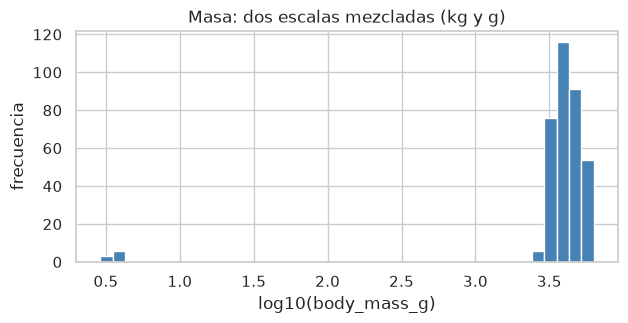

In [20]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(np.log10(sucio["body_mass_g"].dropna()), bins=40, color="steelblue")
ax.set(xlabel="log10(body_mass_g)", ylabel="frecuencia", title="Masa: dos escalas mezcladas (kg y g)")
plt.show()

**Criterios típicos** (siempre documentados):
* **Códigos centinela** (`-999`, `0`, `9999`, `"."`, `"NA"`): convertirlos a `NaN`.
* **Unidades:** si la regla es inequívoca (masa < 100 ⇒ estaba en kg), convertir; si no, marcar y consultar.
* **Fuera de rango plausible:** a `NaN` si es imposible; si solo es raro, **no** se toca aquí (eso es un valor atípico y se estudia en la sesión 3).

### 🟢 Ejercicio 3 · Normaliza las categorías.

A partir de `sin_dup` sin duplicados por llave (`sin_dup.drop_duplicates(subset=["id_muestra"])`), crea `limpio` con `species`, `island` y `sex` normalizadas a `Adelie/Chinstrap/Gentoo`, `Biscoe/Dream/Torgersen` y `Male/Female` (con `"."` convertido a `NaN`). Verifica con `value_counts(dropna=False)` que no queden variantes.

* La siguiente celda muestra una solución posible.

In [21]:
mapa_sexo = {"male": "Male", "m": "Male", "female": "Female", "f": "Female"}
limpio = sin_dup.drop_duplicates(subset=["id_muestra"]).assign(
    species=lambda d: d["species"].str.strip().str.lower().map(mapa_especie),
    island=lambda d: d["island"].str.strip().str.title(),
    sex=lambda d: d["sex"].str.strip().str.lower().map(mapa_sexo),
)
[limpio[c].value_counts(dropna=False).to_dict() for c in ["species", "island", "sex"]]

[{'Adelie': 152, 'Gentoo': 124, 'Chinstrap': 68},
 {'Biscoe': 168, 'Dream': 124, 'Torgersen': 52},
 {'Male': 168, 'Female': 165, nan: 11}]

### 🟢 Ejercicio 4 · Rangos y unidades.

En `limpio`:
1. Convierte a gramos las masas que están en kg (valores < 100).
2. Pon en `NaN` las aletas fuera de 150 a 250 mm y los picos fuera de 30 a 65 mm.
3. Reporta **cuántos valores** cambió cada regla y compara `describe()` antes y después.

**Nota:** con *Copy-on-Write* la forma correcta de modificar `limpio` es `limpio.loc[mascara, "columna"] = valor`.

* La siguiente celda muestra una solución posible.

In [22]:
columnas_num = ["bill_length_mm", "flipper_length_mm", "body_mass_g"]
antes = limpio[columnas_num].describe().T

en_kg = limpio["body_mass_g"] < 100
aleta_mala = limpio["flipper_length_mm"].notna() & ~limpio["flipper_length_mm"].between(150, 250)
pico_malo = limpio["bill_length_mm"].notna() & ~limpio["bill_length_mm"].between(30, 65)

limpio.loc[en_kg, "body_mass_g"] = limpio.loc[en_kg, "body_mass_g"] * 1000
limpio.loc[aleta_mala, "flipper_length_mm"] = np.nan
limpio.loc[pico_malo, "bill_length_mm"] = np.nan

despues = limpio[columnas_num].describe().T
cambios = {"kg a g": int(en_kg.sum()), "aletas a NaN": int(aleta_mala.sum()), "picos a NaN": int(pico_malo.sum())}
cambios, pd.concat({"antes": antes[["min", "mean", "max"]], "después": despues[["min", "mean", "max"]]}, axis=1).round(1)

({'kg a g': 8, 'aletas a NaN': 4, 'picos a NaN': 2},
                    antes                 después                
                      min    mean     max     min    mean     max
 bill_length_mm      32.1    49.5   999.0    32.1    43.9    59.6
 flipper_length_mm -999.0   198.8  2100.0   172.0   200.9   231.0
 body_mass_g          2.9  4117.8  6300.0  2700.0  4202.4  6300.0)

### 🔴 Reto 2 · Validador de reglas.

Escribe `validar(df, reglas)` donde `reglas` es un diccionario `{columna: (minimo, maximo)}` y devuelve un *dataframe* con, por columna, `n_fuera_de_rango`, `pct_fuera_de_rango` y hasta 5 ejemplos. Aplícalo a `sucio` y a `limpio`. Este tipo de función es muy útil en el proyecto integrador.

* La siguiente celda muestra una solución posible.

In [23]:
def validar(df, reglas):
    filas = []
    for columna, (minimo, maximo) in reglas.items():
        serie = df[columna]
        fuera = serie.notna() & ~serie.between(minimo, maximo)
        filas.append({"columna": columna, "rango": f"[{minimo}, {maximo}]",
                      "n_fuera_de_rango": int(fuera.sum()),
                      "pct_fuera_de_rango": round(100 * fuera.mean(), 2),
                      "ejemplos": serie[fuera].head(5).tolist()})
    return pd.DataFrame(filas).set_index("columna")

reglas = {"bill_length_mm": (30, 65), "bill_depth_mm": (12, 23),
          "flipper_length_mm": (150, 250), "body_mass_g": (2500, 6500)}
validar(sucio, reglas)

,rango,n_fuera_de_rango,pct_fuera_de_rango,ejemplos
columna,,,,
bill_length_mm,"[30, 65]",2,0.56,"[999.0, 999.0]"
bill_depth_mm,"[12, 23]",0,0.00,[]
flipper_length_mm,"[150, 250]",4,1.13,"[-999.0, 0.0, -999.0, 2100.0]"
body_mass_g,"[2500, 6500]",9,2.54,"[3.4, 3.775, 3.9, 4.1, 3.5]"


* La siguiente celda aplicará el validador a `limpio` (requiere el reto 2 y el ejercicio 4).

In [24]:
validar(limpio, reglas) if "validar" in globals() and limpio is not None else None

,rango,n_fuera_de_rango,pct_fuera_de_rango,ejemplos
columna,,,,
bill_length_mm,"[30, 65]",0,0.0,[]
bill_depth_mm,"[12, 23]",0,0.0,[]
flipper_length_mm,"[150, 250]",0,0.0,[]
body_mass_g,"[2500, 6500]",0,0.0,[]


---
## 3. Mecanismos de faltantes y cómo perfilarlos (15 min).

| Mecanismo | La probabilidad de faltar depende de… | Ejemplo | Consecuencia |
|---|---|---|---|
| **MCAR** (*Missing Completely At Random*) | nada: azar puro | Se cae una hoja del cuaderno de campo | Eliminar filas solo reduce *n*; no sesga |
| **MAR** (*Missing At Random*) | **otras variables observadas** | Falta la edad más en tercera clase | Sesga si se ignora; se corrige condicionando (imputar por grupo) |
| **MNAR** (*Missing Not At Random*) | **el propio valor faltante** | Los de ingreso alto no reportan su ingreso | Sesga, y los datos solos no pueden demostrarlo ni corregirlo |

**Advertencia:** no existe una prueba que confirme MCAR o MAR con certeza. Con los datos solo se puede **descartar** MCAR (si la falta depende de algo observado); MNAR se argumenta con conocimiento del dominio.

### Simulación: el mismo *dataset* con tres mecanismos.

Se tomarán las masas completas de `penguins`, se les quitará cerca de un tercio de los valores con cada mecanismo y se comparará la media observada con la verdadera.

* La siguiente celda simulará los tres mecanismos y guardará las columnas `masa_MCAR`, `masa_MAR` y `masa_MNAR`.

In [25]:
completos = pinguinos.dropna(subset=["body_mass_g"]).reset_index(drop=True)
masa_real = completos["body_mass_g"]

probabilidades = {
    "MCAR": np.full(len(completos), 0.30),
    "MAR": np.where(completos["species"] == "Gentoo", 0.60, 0.15),
    "MNAR": 0.6 / (1 + np.exp(-(masa_real - 4500) / 300)),
}
sim = completos[["species", "body_mass_g"]].copy()
for nombre, p in probabilidades.items():
    sim[f"masa_{nombre}"] = masa_real.mask(rng.random(len(sim)) < p)
masa_real.mean().round(1)

np.float64(4201.8)

* La siguiente celda comparará el porcentaje de faltantes, la media observada y el sesgo de cada mecanismo.

In [26]:
resumen_sim = pd.DataFrame({
    "% faltante": sim.filter(like="masa_").isna().mean() * 100,
    "media observada": sim.filter(like="masa_").mean(),
}).round(1)
resumen_sim["sesgo vs. real"] = (resumen_sim["media observada"] - masa_real.mean()).round(1)
resumen_sim

,% faltante,media observada,sesgo vs. real
masa_MCAR,33.0,4182.4,-19.4
masa_MAR,25.1,4033.0,-168.8
masa_MNAR,21.6,3977.5,-224.3


* La siguiente celda perfilará por especie la proporción de faltantes de cada mecanismo.

In [27]:
sim.filter(like="masa_").isna().groupby(sim["species"]).mean().round(2)

,masa_MCAR,masa_MAR,masa_MNAR
species,,,
Adelie,0.36,0.09,0.06
Chinstrap,0.22,0.10,0.04
Gentoo,0.36,0.53,0.50


* **MCAR:** la media casi no cambia y la proporción de faltantes es pareja entre especies.
* **MAR:** la falta es mucho mayor en Gentoo (se ve en el perfil) y la media observada **subestima** porque se pierden los más pesados. Como la causa (especie) está observada, se puede corregir condicionando en ella.
* **MNAR:** también subestima, pero el perfil por especie **no** revela la causa completa: depende del valor que no se ve.

### Perfilar faltantes: conteos, patrones y mapa.

Los conteos por columna ya los da `perfil_rapido` (ejercicio 1). Para decidir, interesa además **qué columnas faltan juntas** y **dónde** se concentran los faltantes.

* La siguiente celda mostrará los **patrones**: qué combinaciones de columnas faltan juntas.

In [28]:
pinguinos.isna().value_counts().rename("n_filas")

species  island  bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g  sex  
False    False   False           False          False              False        False    333
                                                                                True       9
                 True            True           True               True         True       2
Name: n_filas, dtype: int64

* La siguiente celda dibujará un mapa de faltantes, en el que cada línea oscura es un `NaN`.

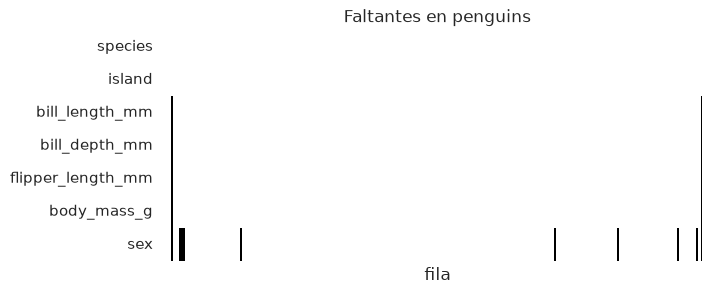

In [29]:
fig, ax = plt.subplots(figsize=(7, 3))
sns.heatmap(pinguinos.isna().T, cbar=False, cmap="Greys", ax=ax)
ax.set(xlabel="fila", title="Faltantes en penguins")
ax.set_xticks([])
plt.show()

### 🟢 Ejercicio 5 · ¿MCAR, MAR o MNAR?

Clasifica cada caso y justifica en una frase:
1. En una encuesta de salud, las personas con mayor consumo de alcohol tienden a no contestar la pregunta sobre consumo de alcohol.
2. Un lector de código de barras falla al azar en 2% de las lecturas.
3. En `tips`, el mesero olvidó anotar la propina más a menudo en las cenas de fin de semana (cuando hay más trabajo), y `day` y `time` sí están registrados.
4. En `penguins`, a 2 pingüinos les faltan **todas** las medidas.

**✅ Respuesta sugerida:**

1. **MNAR:** la falta depende del propio valor (consumo alto ⇒ no responde).
2. **MCAR:** la falla no depende de ninguna variable.
3. **MAR:** depende de `day` y `time`, que están observadas; se puede corregir condicionando en ellas.
4. Lo más probable es que sean individuos **no medidos** (se registró su presencia pero no se tomaron las medidas). Con 2 filas sin ninguna medida no hay forma razonable de imputar: se **eliminan** y se documenta. Por sí solos no permiten distinguir el mecanismo, pero son 2 de 344 y el impacto es mínimo.

---
## 4. Tratamiento de faltantes y su efecto (30 min).

| Estrategia | Cuándo | Costo |
|---|---|---|
| **Eliminar filas** (`dropna`) | Pocos faltantes y MCAR | Pierde *n*; sesga si no es MCAR |
| **Eliminar columna** | La columna casi no tiene datos o no es relevante | Pierde la variable |
| **Imputar media o mediana global** | Rápido, pocos faltantes | **Reduce la varianza**, crea un pico artificial, distorsiona relaciones |
| **Imputar por grupo** (`groupby().transform`) | MAR con la causa observada | Mejor, pero sigue subestimando la variabilidad dentro del grupo |
| **Indicador de faltante** | Siempre que se impute: conserva la información de *que faltaba* | Una columna más |
| Imputación múltiple o con modelos | Análisis inferencial serio | Más complejo; fuera del alcance de hoy |

Se usará el escenario **MAR** de la simulación, donde se conoce la verdad.

* La siguiente celda aplicará las cuatro estrategias y creará el indicador `faltaba`.

In [30]:
mar = sim[["species", "body_mass_g", "masa_MAR"]].assign(
    elim=lambda d: d["masa_MAR"],
    imp_media=lambda d: d["masa_MAR"].fillna(d["masa_MAR"].mean()),
    imp_mediana=lambda d: d["masa_MAR"].fillna(d["masa_MAR"].median()),
    imp_grupo=lambda d: d["masa_MAR"].fillna(d.groupby("species")["masa_MAR"].transform("median")),
    faltaba=lambda d: d["masa_MAR"].isna(),
)
mar.head()

,species,body_mass_g,masa_MAR,elim,imp_media,imp_mediana,imp_grupo,faltaba
0,Adelie,3750.0,3750.0,3750.0,3750.000000,3750.0,3750.0,False
1,Adelie,3800.0,NaN,NaN,4033.007812,3800.0,3650.0,True
2,Adelie,3250.0,NaN,NaN,4033.007812,3800.0,3650.0,True
3,Adelie,3450.0,3450.0,3450.0,3450.000000,3450.0,3450.0,False
4,Adelie,3650.0,3650.0,3650.0,3650.000000,3650.0,3650.0,False


* La siguiente celda comparará conteo, media, mediana y desviación estándar de cada estrategia contra la verdad.

In [31]:
tabla = mar[["body_mass_g", "elim", "imp_media", "imp_mediana", "imp_grupo"]].agg(["count", "mean", "median", "std"]).T.round(1)
tabla.index = ["real (sin faltantes)", "eliminar", "media global", "mediana global", "mediana por especie"]
tabla

,count,mean,median,std
real (sin faltantes),342.0,4201.8,4050.0,802.0
eliminar,256.0,4033.0,3800.0,755.1
media global,342.0,4033.0,4033.0,653.0
mediana global,342.0,3974.4,3800.0,660.8
mediana por especie,342.0,4213.3,4000.0,786.8


* La siguiente celda graficará el efecto de tres estrategias sobre la distribución.

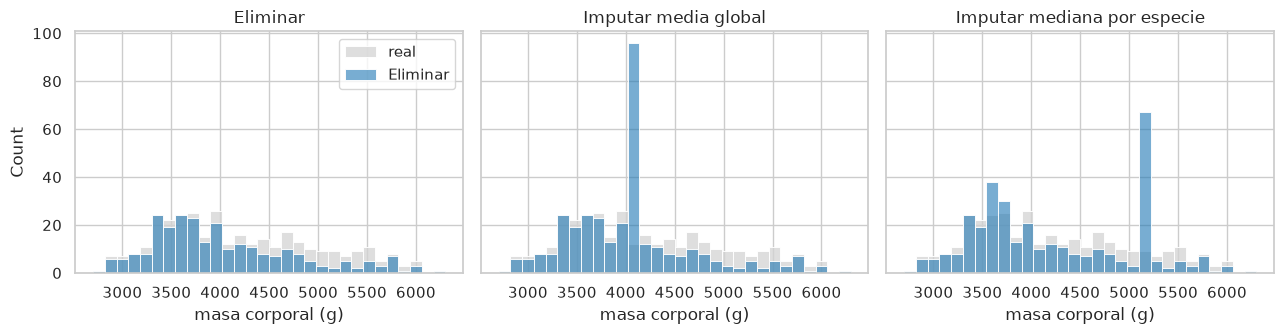

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharex=True, sharey=True)
for ax, columna, titulo in zip(axes, ["elim", "imp_media", "imp_grupo"],
                               ["Eliminar", "Imputar media global", "Imputar mediana por especie"]):
    sns.histplot(mar["body_mass_g"], bins=30, color="lightgray", label="real", ax=ax)
    sns.histplot(mar[columna].dropna(), bins=30, color="tab:blue", alpha=0.6, label=titulo, ax=ax)
    ax.set(title=titulo, xlabel="masa corporal (g)")
axes[0].legend()
plt.tight_layout()
plt.show()

**Lecturas clave:**
* **Eliminar** con MAR sesga la media hacia abajo, porque se perdieron Gentoo pesados.
* **Media o mediana global** crea un **pico artificial** y **encoge la desviación estándar**: subestima la variabilidad y hará que, más adelante, los intervalos de confianza sean falsamente estrechos.
* **Por grupo** recupera mejor la media y la forma, porque condiciona en la variable que explica la falta.
* Conviene guardar siempre el **indicador** (`faltaba`) para revisar después si los imputados se comportan distinto.

### 4.1 Decidir el tratamiento: preguntas y consecuencias.

Antes de escribir `dropna` o `fillna` conviene responder, por escrito:

| Pregunta | Si la respuesta es… | Decisión razonable | Consecuencia que hay que reportar |
|---|---|---|---|
| ¿Cuántos faltan? | Muy pocos (≈ 1 a 2%) | Eliminar o imputar da casi igual | Cuántas filas se perdieron |
| ¿De qué depende la falta? | De una variable observada (MAR) | Imputar **por grupo** o analizar por estratos | Que la imputación supone MAR |
| | Del propio valor (MNAR) | No hay corrección con los datos; análisis de sensibilidad | Que el resultado puede estar sesgado y en qué dirección |
| ¿Para qué se usará la variable? | Para describir su distribución | Evitar imputar con un valor único | La varianza y la forma cambian |
| | Para relacionarla con otras | Evitar la imputación global | Las correlaciones se atenúan |
| ¿Se eliminan filas completas? | `dropna()` sin `subset` | Casi nunca: usar `subset` con las columnas del análisis | La muestra puede dejar de representar a la población |

Las dos celdas siguientes muestran las dos consecuencias menos evidentes.

**Consecuencia 1: imputar con la media global debilita las relaciones.** Los valores imputados son todos iguales, sin importar la aleta del pingüino, así que la correlación aleta–masa baja.

* La siguiente celda comparará la correlación aleta–masa con los datos reales y con dos imputaciones del escenario MAR.

In [33]:
aleta = completos["flipper_length_mm"]
{"real": round(float(aleta.corr(mar["body_mass_g"])), 3),
 "imputación con media global": round(float(aleta.corr(mar["imp_media"])), 3),
 "imputación con mediana por especie": round(float(aleta.corr(mar["imp_grupo"])), 3)}

{'real': 0.871,
 'imputación con media global': 0.674,
 'imputación con mediana por especie': 0.876}

Con la media global la correlación baja de 0.87 a cerca de 0.67: un análisis posterior concluiría que la relación es más débil de lo que es. Con la mediana por especie casi no cambia, porque la especie explica tanto la falta como buena parte de la aleta y de la masa.

**Consecuencia 2: `dropna()` sin `subset` cambia la población.** En `titanic`, `deck` falta en 77% de las filas. Eliminar toda fila con algún faltante deja una muestra dominada por primera clase, porque las cubiertas se registraban sobre todo para esos pasajeros.

* La siguiente celda comparará el tamaño, la composición por clase y la supervivencia de `titanic` completo y después de `dropna()`.

In [34]:
sin_faltantes = titanic.dropna()
pd.DataFrame({
    "completo": titanic["class"].value_counts(normalize=True),
    "tras dropna()": sin_faltantes["class"].value_counts(normalize=True),
}).round(3), len(titanic), len(sin_faltantes), round(float(titanic["survived"].mean()), 3), round(float(sin_faltantes["survived"].mean()), 3)

(        completo  tras dropna()
 class                          
 First      0.242          0.863
 Second     0.207          0.082
 Third      0.551          0.055,
 891,
 182,
 0.384,
 0.676)

De 891 pasajeros quedan 182; la primera clase pasa de 24% a 86% de la muestra y la tasa de supervivencia, de 38% a 68%. Cualquier conclusión sobre esa muestra describe a otra población. Por eso se usa `dropna(subset=[...])` solo con las columnas que necesita cada análisis.

---
## 5. Ejercicio de la sesión (20 min + práctica).

### Parte A · `titanic`.

### 🟢 Ejercicio 6 · Cuantifica los faltantes.

Calcula el número y el porcentaje de faltantes de `age`, `deck` y `embark_town`. ¿Qué harías con cada una a primera vista?

* La siguiente celda muestra una solución posible.

In [35]:
columnas = ["age", "deck", "embark_town"]
pd.DataFrame({"n_faltantes": titanic[columnas].isna().sum(),
              "pct": (titanic[columnas].isna().mean() * 100).round(1)})

,n_faltantes,pct
age,177,19.9
deck,688,77.2
embark_town,2,0.2


**✅ Respuesta sugerida:**

* `age` (19.9%): demasiados para eliminar sin perder información; candidata a imputar **por grupo** con indicador.
* `deck` (77.2%): la mayoría falta; imputar inventaría datos. Es mejor tratarla como categoría `"Desconocido"` o no usarla.
* `embark_town` (2 filas): tan pocos que eliminar o imputar con la moda no cambia nada; se documenta.

### 🟢 Ejercicio 7 · ¿La falta de `age` depende de `class`?

Calcula la proporción de `age` faltante por `class` (y, si quieres, por `sex` y por `embark_town`). Con base en eso, ¿es plausible que sea MCAR? Haz una gráfica de barras de la proporción por clase.

* La siguiente celda muestra una solución posible.

In [36]:
falta_edad = titanic["age"].isna()
por_clase = falta_edad.groupby(titanic["class"]).mean().reindex(["First", "Second", "Third"])
por_clase.round(3), falta_edad.groupby(titanic["sex"]).mean().round(3), falta_edad.groupby(titanic["embark_town"]).mean().round(3)

(class
 First     0.139
 Second    0.060
 Third     0.277
 Name: age, dtype: float64,
 sex
 female    0.169
 male      0.215
 Name: age, dtype: float64,
 embark_town
 Cherbourg      0.226
 Queenstown     0.636
 Southampton    0.140
 Name: age, dtype: float64)

* La siguiente celda graficará el porcentaje de edades faltantes por clase (requiere `por_clase`).

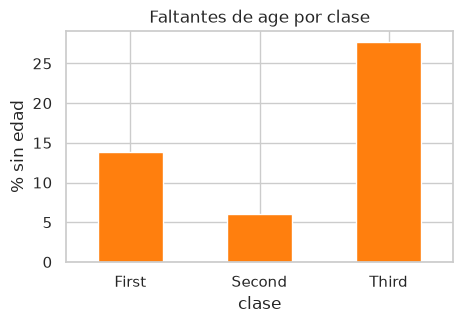

In [37]:
if "por_clase" in globals():
    ax = por_clase.mul(100).plot.bar(color="tab:orange", rot=0, figsize=(5, 3))
    ax.set(ylabel="% sin edad", xlabel="clase", title="Faltantes de age por clase")
    plt.show()

**✅ Respuesta sugerida:**

La falta de `age` es mucho mayor en **tercera clase** (27.7%) que en primera (13.9%) y segunda (6.0%), y también varía por puerto (63.6% en Queenstown). **No parece MCAR**: depende de variables observadas, lo que es compatible con **MAR** (aunque no se puede descartar MNAR). Por eso conviene imputar condicionando en `class` y `sex`.

### 🟢 Ejercicio 8 · Mediana global vs. mediana por `class` y `sex`.

1. Crea `age_med_global` (imputando con la mediana global) y `age_med_grupo` (con la mediana por `class` y `sex`, usando `groupby(...).transform("median")`), además de un indicador `age_faltaba`.
2. Compara media, mediana y desviación estándar de `age` original y de las dos versiones imputadas.
3. Grafica las tres distribuciones. ¿Qué estrategia distorsiona menos? ¿Qué le pasa a la desviación estándar?

* La siguiente celda muestra una solución posible.

In [38]:
titanic_imp = titanic.assign(
    age_faltaba=lambda d: d["age"].isna(),
    age_med_global=lambda d: d["age"].fillna(d["age"].median()),
    age_med_grupo=lambda d: d["age"].fillna(d.groupby(["class", "sex"])["age"].transform("median")),
)
medianas_grupo = titanic.groupby(["class", "sex"])["age"].median().unstack()
comparacion = titanic_imp[["age", "age_med_global", "age_med_grupo"]].agg(["count", "mean", "median", "std"]).T.round(2)
medianas_grupo, comparacion

(sex     female  male
 class               
 First     35.0  40.0
 Second    28.0  30.0
 Third     21.5  25.0,
                 count   mean  median    std
 age             714.0  29.70    28.0  14.53
 age_med_global  891.0  29.36    28.0  13.02
 age_med_grupo   891.0  29.11    26.0  13.30)

* La siguiente celda graficará las tres distribuciones de edad (requiere `titanic_imp`).

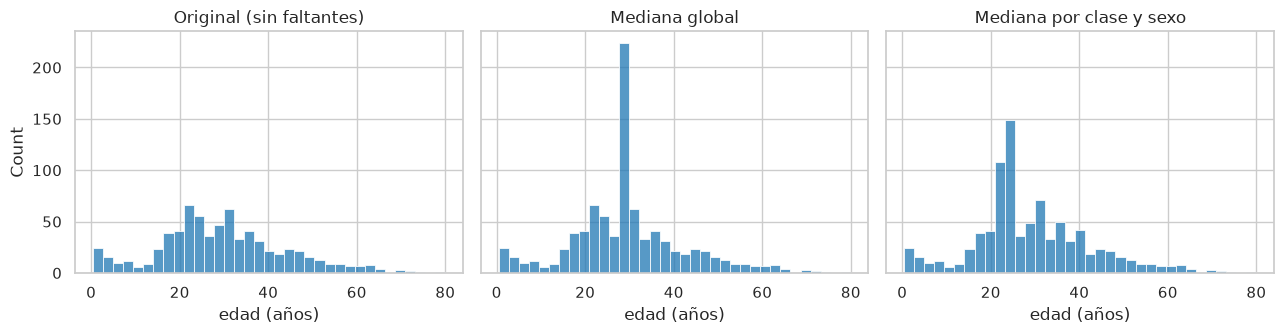

In [39]:
if "titanic_imp" in globals():
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharex=True, sharey=True)
    for ax, columna, titulo in zip(axes, ["age", "age_med_global", "age_med_grupo"],
                                   ["Original (sin faltantes)", "Mediana global", "Mediana por clase y sexo"]):
        sns.histplot(titanic_imp[columna].dropna(), bins=35, ax=ax, color="tab:blue")
        ax.set(title=titulo, xlabel="edad (años)")
    plt.tight_layout()
    plt.show()

**✅ Respuesta sugerida:**

* La **mediana global** (28 años) mete 177 valores idénticos: aparece una barra enorme en 28 y la desviación estándar baja de 14.5 a 13.0.
* La **mediana por clase y sexo** reparte los imputados entre varios valores (de 21.5 a 40 años), conserva mejor la forma y la relación edad–clase (primera clase es mayor) y reduce menos la desviación estándar (13.3).
* Ambas **subestiman la variabilidad**, porque todos los imputados de un grupo valen lo mismo. Por eso se guarda `age_faltaba`.

### 🔴 Reto 3 · `deck` y `embark_town`, y un adelanto de inferencia.

1. Propón y aplica un tratamiento para `deck` (77% faltante) y para `embark_town` (2 filas). Justifica.
2. **Adelanto de la sesión 6:** con `pd.crosstab` y `scipy.stats.chi2_contingency`, prueba si la falta de `age` es independiente de `class`. Interpreta el valor *p* con cuidado.
3. ¿La tasa de supervivencia es distinta entre quienes tienen y no tienen `age` registrada? ¿Qué implicaría para un análisis que simplemente borra esas filas?

* La siguiente celda muestra una solución posible.

In [40]:
from scipy import stats

moda_puerto = titanic["embark_town"].mode()[0]
titanic_tratado = titanic.assign(
    deck=lambda d: d["deck"].fillna("Desconocido"),
    embark_town=lambda d: d["embark_town"].fillna(moda_puerto),
)
tabla_edad = pd.crosstab(titanic["class"], titanic["age"].isna().rename("age_faltante"))
chi2, valor_p, grados, esperadas = stats.chi2_contingency(tabla_edad)
supervivencia = titanic["survived"].groupby(titanic["age"].isna().rename("age_faltante")).mean().round(3)
titanic_tratado["deck"].value_counts(), moda_puerto, tabla_edad, round(chi2, 1), f"{valor_p:.2g}", supervivencia

(deck
 Desconocido    688
 C               59
 B               47
 D               33
 E               32
 A               15
 F               13
 G                4
 Name: count, dtype: int64,
 'Southampton',
 age_faltante  False  True 
 class                     
 First           186     30
 Second          173     11
 Third           355    136,
 np.float64(46.1),
 '9.9e-11',
 age_faltante
 False    0.406
 True     0.294
 Name: survived, dtype: float64)

**✅ Respuesta sugerida:**

1. `deck`: categoría explícita `"Desconocido"` (no se inventan cubiertas). `embark_town`: moda (Southampton), porque son solo 2 filas.
2. χ² ≈ 46.1 con 2 grados de libertad y *p* ≈ 1e-10: si la falta fuera independiente de la clase, una asociación así sería muy improbable. Esto **descarta MCAR** respecto a `class`, pero **no prueba** que sea MAR.
3. Sobreviven menos quienes no tienen edad (29.4% contra 40.6%): borrar esas filas **sobrestimaría** la supervivencia.

### Parte B · Auditoría de `penguins` y *dataset* limpio para las siguientes sesiones.

### 🟢 Ejercicio 9 · Aplica la misma auditoría a `penguins` (el original, no `sucio`).

1. Recorre la lista de verificación: tipos, duplicados, categorías (`value_counts`), rangos y faltantes por columna y por patrón.
2. Identifica las **filas sin medidas** y las filas con **`sex` faltante**. ¿La falta de `sex` se concentra en alguna especie o isla?
3. Decide y justifica: ¿qué haces con las filas sin medidas? ¿Imputas `sex`?

* La siguiente celda muestra una solución posible.

In [41]:
medidas = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
sin_medidas = pinguinos[medidas].isna().all(axis=1)
sexo_falta = pinguinos["sex"].isna()
{
    "duplicados exactos": int(pinguinos.duplicated().sum()),
    "categorías": [pinguinos[c].value_counts(dropna=False).to_dict() for c in ["species", "island", "sex"]],
    "rangos": pinguinos[medidas].agg(["min", "max"]).to_dict(),
    "filas sin medidas": int(sin_medidas.sum()),
    "sex faltante": int(sexo_falta.sum()),
    "sex faltante y sin medidas": int((sexo_falta & sin_medidas).sum()),
    "sex faltante por especie e isla": pinguinos[sexo_falta].groupby(["species", "island"]).size().to_dict(),
}

{'duplicados exactos': 0,
 'categorías': [{'Adelie': 152, 'Gentoo': 124, 'Chinstrap': 68},
  {'Biscoe': 168, 'Dream': 124, 'Torgersen': 52},
  {'MALE': 168, 'FEMALE': 165, nan: 11}],
 'rangos': {'bill_length_mm': {'min': 32.1, 'max': 59.6},
  'bill_depth_mm': {'min': 13.1, 'max': 21.5},
  'flipper_length_mm': {'min': 172.0, 'max': 231.0},
  'body_mass_g': {'min': 2700.0, 'max': 6300.0}},
 'filas sin medidas': 2,
 'sex faltante': 11,
 'sex faltante y sin medidas': 2,
 'sex faltante por especie e isla': {('Adelie', 'Dream'): 1,
  ('Adelie', 'Torgersen'): 5,
  ('Gentoo', 'Biscoe'): 5}}

**✅ Respuesta sugerida:**

* **Duplicados:** no hay. **Categorías:** consistentes, pero `sex` viene en mayúsculas (`MALE`/`FEMALE`); se pasa a `Male`/`Female` para homologar con *Seaborn* y con `sucio`. **Rangos:** plausibles.
* **2 filas sin ninguna medida** (y sin `sex`): no aportan nada al análisis de medidas, así que **se eliminan** y se documenta (2 de 344, 0.6%).
* **`sex` faltante en 11 filas** (9 tras eliminar las 2 anteriores), todas en Adelie (Torgersen y Dream) y Gentoo; ninguna en Chinstrap. **No se imputa**: inventar el sexo sesgaría las comparaciones por sexo de las sesiones 5 y 6. Se deja como `NaN` y cada análisis por sexo excluye esas filas explícitamente.

### *Dataset* limpio de referencia (`data/penguins_limpio.csv`).

Para que **todos empiecen la sesión 3 con los mismos datos**, la siguiente celda aplica las decisiones acordadas y guarda el resultado. Compárala con lo que hiciste en el ejercicio 9.

Decisiones: (1) `sex` → `Male`/`Female`; (2) eliminar las filas sin ninguna medida; (3) **no** imputar `sex`; (4) tipos: `category` para las categóricas e `Int64` para aleta y masa.

* La siguiente celda construirá `penguins_limpio` y lo guardará en `data/`.

In [42]:
medidas = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
penguins_limpio = (
    pinguinos
    .assign(sex=lambda d: d["sex"].str.title())
    .dropna(subset=medidas, how="all")
    .astype({"species": "category", "island": "category", "sex": "category",
             "flipper_length_mm": "Int64", "body_mass_g": "Int64"})
    .reset_index(drop=True)
)
penguins_limpio.to_csv(os.path.join(DATA, "penguins_limpio.csv"), index=False)
len(pinguinos), len(penguins_limpio), penguins_limpio.isna().sum().to_dict()

(344,
 342,
 {'species': 0,
  'island': 0,
  'bill_length_mm': 0,
  'bill_depth_mm': 0,
  'flipper_length_mm': 0,
  'body_mass_g': 0,
  'sex': 9})

### 🔴 Reto 4 · Impacto de las decisiones.

Compara la masa media por especie y sexo en `pinguinos` (original) y en `penguins_limpio`. ¿Cambió algo? ¿Por qué era de esperarse? Después calcula cuánto cambiaría la masa media por especie y sexo si se hubiera imputado `sex` con la **moda** de cada especie: ¿qué sexo "gana" artificialmente?

* La siguiente celda muestra una solución posible.

In [43]:
original = pinguinos.assign(sex=lambda d: d["sex"].str.title()).groupby(["species", "sex"])["body_mass_g"].mean()
limpia = penguins_limpio.groupby(["species", "sex"], observed=True)["body_mass_g"].mean()

moda_sexo = penguins_limpio.groupby("species", observed=True)["sex"].agg(lambda s: s.mode()[0]).astype("str")
sexo_imputado = penguins_limpio["sex"].astype("str").fillna(penguins_limpio["species"].astype("str").map(moda_sexo))
imputado = penguins_limpio.assign(sex=sexo_imputado)

pd.concat({
    "original": original,
    "limpio": limpia,
    "sex imputado con la moda": imputado.groupby(["species", "sex"])["body_mass_g"].mean(),
    "n tras imputar": imputado.groupby(["species", "sex"]).size(),
}, axis=1).round(1)

original  limpio  sex imputado con la moda  n tras imputar
species   sex                                                               
Adelie    Female    3368.8  3368.8                    3379.8              78
          Male      4043.5  4043.5                    4043.5              73
Chinstrap Female    3527.2  3527.2                    3527.2              34
          Male      3939.0  3939.0                    3939.0              34
Gentoo    Female    4679.7  4679.7                    4679.7              58
          Male      5484.8  5484.8                    5429.6              65

**✅ Respuesta sugerida:**

Original y limpio coinciden: las filas eliminadas no tenían medidas, así que no entraban en ningún promedio. Al imputar con la moda, todos los faltantes de Adelie pasan a `Female` y los de Gentoo a `Male`: esos grupos se inflan y mezclan individuos que pueden ser del otro sexo (por ejemplo, la masa media de los machos Gentoo baja de 5484.8 a 5429.6 g), lo que sesga las comparaciones.

---
## ✅ Cierre.

**Hoy vimos:**
* La **lista de verificación de calidad** que se usará en todo el curso.
* Duplicados exactos vs. por llave, y por qué un duplicado sin llave no siempre es un error (`titanic`).
* Inconsistencias: texto, categorías, códigos centinela, rangos imposibles y unidades.
* Mecanismos **MCAR / MAR / MNAR** y cómo perfilarlos.
* Tratamientos y su costo: eliminar sesga si no es MCAR; imputar con un valor único **encoge la varianza** y **atenúa las correlaciones**; imputar por grupo es mejor si la causa está observada; conviene guardar el indicador.
* Decidir antes de limpiar: cuántos faltan, de qué depende la falta, para qué se usará la variable y qué población queda después de eliminar filas.

**Práctica (sin calificación, en Classroom):** terminar los ejercicios 🟢 y verificar que exista `data/penguins_limpio.csv`.

**Próxima sesión (mié 21 oct):** estadística descriptiva, forma de la distribución y valores atípicos (`03_descriptiva_distribuciones.ipynb`), sobre `penguins_limpio`.

<p style="text-align: center"><a rel="license" href="http://creativecommons.org/licenses/by/4.0/"><img alt="Licencia Creative Commons" style="border-width:0" src="https://i.creativecommons.org/l/by/4.0/80x15.png" /></a><br />Esta obra está bajo una <a rel="license" href="http://creativecommons.org/licenses/by/4.0/">Licencia Creative Commons Atribución 4.0 Internacional</a>.</p>
<p style="text-align: center">&copy; José Luis Chiquete Valdivieso. 2017-2026.</p>